# Neutrino-Induced Charm Production: Slow Rescaling Model vs Measurements

Comparison of the **Georgi–Politzer / Barnett Slow Rescaling Model** with historical inclusive experimental measurements from **CHORUS** (2011) and **E531** (1988) on nuclear emulsion targets.

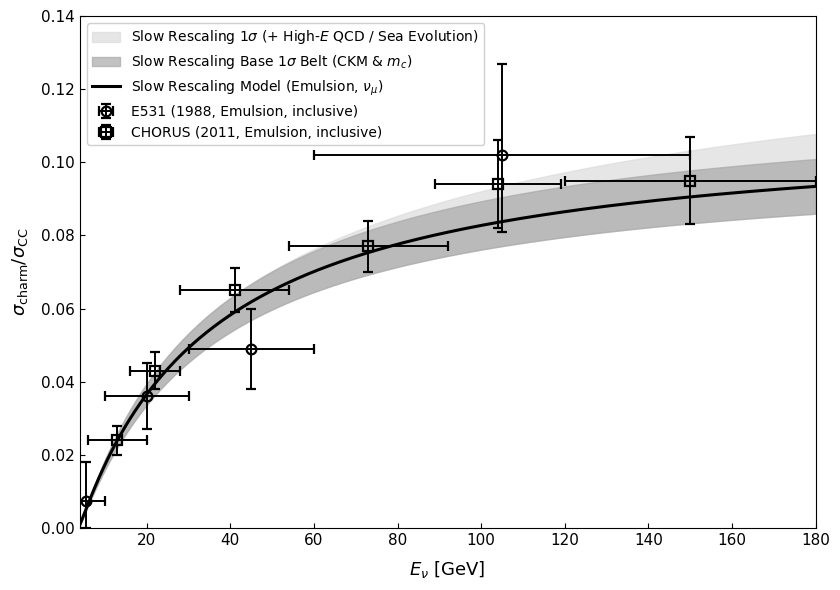

In [5]:
import csv
import math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Resolve CSV location relative to notebook directory or repo root
csv_path = Path("../scripts/diagnostics/measurements/neutrino_charm_cross_section_ratio_vs_enu.csv")
if not csv_path.exists():
    csv_path = Path("scripts/diagnostics/measurements/neutrino_charm_cross_section_ratio_vs_enu.csv")

# 1. Parse historical measurements (inclusive charm production on emulsion)
records = []
with open(csv_path, "r", encoding="utf-8-sig") as f:
    clean_lines = [line for line in f if not line.strip().startswith("#")]
    reader = csv.DictReader(clean_lines)
    for row in reader:
        if row.get("channel", "").strip().lower() != "inclusive":
            continue
        records.append({
            "exp": row["experiment"].strip(),
            "x": float(row["E_nu_GeV"]),
            "dx_lo": float(row["dx_low"]),
            "dx_hi": float(row["dx_high"]),
            "y": float(row["ratio"]),
            "dy_lo": float(row["dy_low"]),
            "dy_hi": float(row["dy_high"]),
        })

# 2. Slow Rescaling Model (Nuclear Emulsion target, nu_mu CC)
m_p = 0.938272
m_c = 1.2729
sigma_m_c = 0.0045
e_thresh = ((m_p + m_c)**2 - m_p**2) / (2.0 * m_p) + 1.50

# Nuclear Emulsion composition (<Z/A> ~ 0.467)
f_p = 0.467
f_n = 1.0 - f_p
u_val_p, d_val_p, sea_q = 0.285, 0.130, 0.035
s_quark = 0.55 * sea_q
d_target = f_p * d_val_p + f_n * u_val_p + sea_q

v_cd, v_cs = 0.22503, 0.97345
r_inf = (v_cd**2 * d_target + v_cs**2 * s_quark) / (d_target + s_quark + (1.0 / 3.0) * sea_q)

alpha = 1.15
e_scale = 28.0
sigma_ethresh = ((m_p + m_c) / m_p) * sigma_m_c
rel_base = 0.08

# Grid covering the measurement range [4, 180] GeV
e_pts = np.linspace(4.0, 180.0, 500)
y_cen = np.zeros_like(e_pts)
y_in_lo = np.zeros_like(e_pts)
y_in_hi = np.zeros_like(e_pts)
y_out_hi = np.zeros_like(e_pts)

for i, x in enumerate(e_pts):
    if x <= e_thresh:
        continue
    kin = ((1.0 - e_thresh / x)**alpha) * (x / (x + e_scale))
    y = r_inf * kin
    dy_dethresh = r_inf * alpha * ((1.0 - e_thresh / x)**(alpha - 1.0)) * (-1.0 / (x + e_scale))
    sigma_kin = abs(dy_dethresh * sigma_ethresh)

    # Inner band: base kinematics + CKM/PDF normalization
    sigma_inner = math.sqrt((kin * rel_base * r_inf)**2 + sigma_kin**2)

    # Outer band: high-E QCD evolution (gluon fusion and strange sea growth)
    rel_high_e = 0.28 * math.log(max(1.0, x / 40.0)) / math.log(1000.0 / 40.0)
    tot_rel = math.sqrt(rel_base**2 + rel_high_e**2)
    sigma_outer_up = math.sqrt((kin * r_inf * tot_rel)**2 + sigma_kin**2)

    y_cen[i] = y
    y_in_lo[i] = max(0.0, y - sigma_inner)
    y_in_hi[i] = y + sigma_inner
    y_out_hi[i] = y + sigma_outer_up

# 3. Plotting
fig, ax = plt.subplots(figsize=(8.5, 6.0))

# Error bands: two shades of grey
ax.fill_between(
    e_pts, y_in_lo, y_out_hi,
    color="#dcdcdc", label=r"Slow Rescaling $1\sigma$ (+ High-$E$ QCD / Sea Evolution)", zorder=1, alpha=0.7
)
ax.fill_between(
    e_pts, y_in_lo, y_in_hi,
    color="#a8a8a8", label=r"Slow Rescaling Base $1\sigma$ Belt (CKM & $m_c$)", zorder=2, alpha=0.7
)

# Continuous black line for central model
ax.plot(
    e_pts, y_cen,
    color="black", lw=2.2, label=r"Slow Rescaling Model (Emulsion, $\nu_\mu$)", zorder=3
)

# Black markers for historical experimental data
labels_map = {
    "E531": "E531 (1988, Emulsion, inclusive)",
    "CHORUS": "CHORUS (2011, Emulsion, inclusive)"
}
for exp, marker in [("E531", "o"), ("CHORUS", "s")]:
    pts = [r for r in records if r["exp"] == exp]
    if not pts:
        continue
    x = [p["x"] for p in pts]
    y = [p["y"] for p in pts]
    x_err = [[p["dx_lo"] for p in pts], [p["dx_hi"] for p in pts]]
    y_err = [[p["dy_lo"] for p in pts], [p["dy_hi"] for p in pts]]
    ax.errorbar(
        x, y, xerr=x_err, yerr=y_err,
        fmt=marker, mfc="none", mec="black", mew=1.6, markersize=7,
        ecolor="black", elinewidth=1.4, capsize=3.5, capthick=1.2,
        label=labels_map[exp], zorder=4
    )

ax.set_xlim(4.0, 180.0)
ax.set_ylim(0.0, 0.14)
ax.set_xlabel(r"$E_\nu$ [GeV]", fontsize=13, labelpad=8)
ax.set_ylabel(r"$\sigma_{\mathrm{charm}} / \sigma_{\mathrm{CC}}$", fontsize=13, labelpad=8)
ax.tick_params(axis="both", which="major", labelsize=11, direction="in")
# ax.grid(True, which="major", linestyle="--", alpha=0.45, color="gray")

leg = ax.legend(loc="upper left", fontsize=10.0, frameon=True, framealpha=0.92, facecolor="white")
leg.get_frame().set_linewidth(1.0)

plt.tight_layout()
plt.show()


In [ ]:
import ROOT
ROOT.gROOT.SetBatch(True)

f = ROOT.TFile.Open("/eos/user/i/idioniso/snd-numu-charm/charm_diagnostic_nu14_2022.root")
c1 = f.Get("Canvases/c_species_fractions_vs_nu_energy")
c2 = f.Get("Canvases/c_species_fractions_vs_nu_energy_nu_only")
c3 = f.Get("Canvases/c_species_fractions_vs_nu_energy_antinu_only")

c_comb = ROOT.TCanvas("c_comb", "Charm Species Fractions Combined", 2400, 750)
c_comb.Divide(3, 1)

for idx, c_src in enumerate([c1, c2, c3], start=1):
    pad = c_comb.cd(idx)
    pad.SetLogx()
    pad.SetGrid()
    pad.SetLeftMargin(0.12)
    pad.SetRightMargin(0.06)
    pad.SetTopMargin(0.08)
    pad.SetBottomMargin(0.12)
    for prim in c_src.GetListOfPrimitives():
        prim.Draw("same" if prim.InheritsFrom("TGraph") or prim.InheritsFrom("TLegend") else "")
    pad.Update()

c_comb.Update()

Successfully generated 3-level efficiency plot.


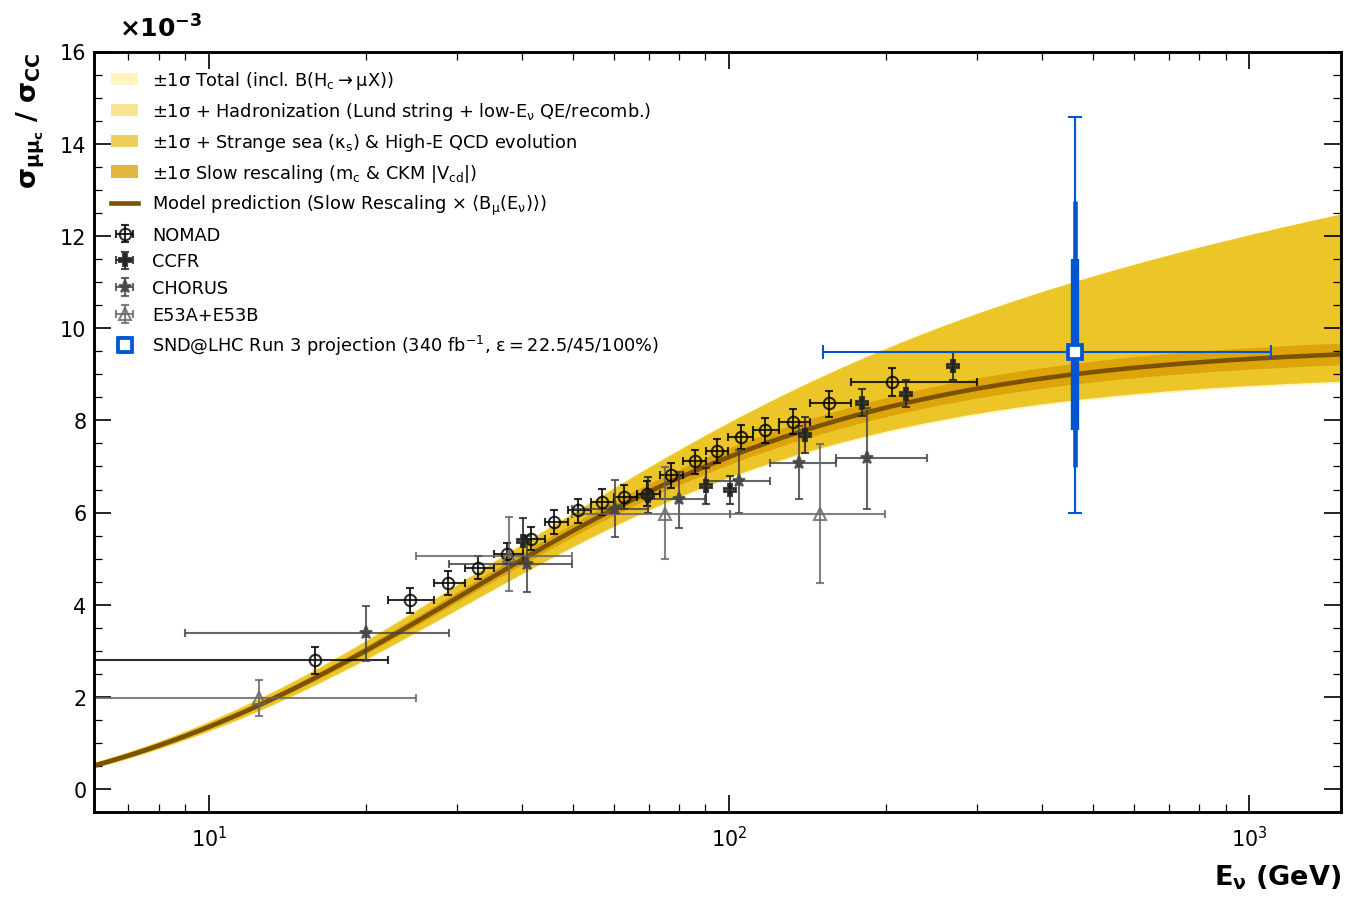

In [37]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

E_grid = np.logspace(np.log10(6.0), np.log10(1500.0), 180)

def calc_curve(
    E,
    mc=1.2729,
    Vcd=0.22503,
    Vcs=0.97345,
    kappa_s=0.55,
    nlo_scale=1.0,
    target='isoscalar',
    alpha=1.15,
    e_scale=28.0,
    f_lmd_thresh=0.30,
    tau=18.0,
    br_Dp=0.160,
    br_D0=0.067,
    br_Ds=0.068,
    br_Lc=0.035,
):
    m_p = 0.938272
    e_thresh = ((m_p + mc) ** 2 - m_p**2) / (2.0 * m_p) + 1.50

    f_p = (
        0.50
        if target == 'isoscalar'
        else (0.467 if target == 'emulsion' else 74.0 / 183.84)
    )
    f_n = 1.0 - f_p

    u_val_p, d_val_p, sea_q = 0.285, 0.130, 0.035
    s_quark = kappa_s * sea_q
    d_target = f_p * d_val_p + f_n * u_val_p + sea_q

    r_inf = (
        ((Vcd**2 * d_target) + (Vcs**2 * s_quark))
        / (d_target + s_quark + (1.0 / 3.0) * sea_q)
        * nlo_scale
    )

    kin = np.where(
        E > e_thresh, ((1.0 - e_thresh / E) ** alpha) * (E / (E + e_scale)), 0.0
    )
    R_c = r_inf * kin

    decay = np.exp(-(np.maximum(E, 4.5) - 4.5) / tau)
    f_thresh = {'D0': 0.45, 'D+': 0.18, 'Lambda_c': f_lmd_thresh, 'Ds+': 0.04}
    f_inf = {'D0': 0.58, 'D+': 0.23, 'Lambda_c': 0.08, 'Ds+': 0.09}

    raw = {sp: f_inf[sp] + (f_thresh[sp] - f_inf[sp]) * decay for sp in f_inf}
    tot = sum(raw.values())
    f = {sp: raw[sp] / tot for sp in raw}

    br = {'D0': br_D0, 'D+': br_Dp, 'Ds+': br_Ds, 'Lambda_c': br_Lc}
    B_mu = sum(f[sp] * br[sp] for sp in br)

    return R_c * B_mu * 1e3

y_nominal = calc_curve(E_grid)

var_mc_lo = (np.maximum(0.0, y_nominal - calc_curve(E_grid, mc=1.3529))) ** 2
var_mc_hi = (np.maximum(0.0, calc_curve(E_grid, mc=1.1929) - y_nominal)) ** 2
var_ckm = (
    (calc_curve(E_grid, Vcd=0.232) - calc_curve(E_grid, Vcd=0.218)) / 2.0
) ** 2

sigma_cumul_1_lo = np.sqrt(var_mc_lo + var_ckm)
sigma_cumul_1_hi = np.sqrt(var_mc_hi + var_ckm)

var_sea = (
    (calc_curve(E_grid, kappa_s=0.61) - calc_curve(E_grid, kappa_s=0.49)) / 2.0
) ** 2

delta_qcd_up = np.where(
    E_grid > 40.0, 0.28 * np.log(E_grid / 40.0) / np.log(1000.0 / 40.0), 0.0
)
var_qcd_hi = var_sea + (y_nominal * delta_qcd_up) ** 2
var_qcd_lo = var_sea

sigma_cumul_2_lo = np.sqrt(sigma_cumul_1_lo**2 + var_qcd_lo)
sigma_cumul_2_hi = np.sqrt(sigma_cumul_1_hi**2 + var_qcd_hi)

var_had_thresh = (
    (
        calc_curve(E_grid, f_lmd_thresh=0.38)
        - calc_curve(E_grid, f_lmd_thresh=0.22)
    )
    / 2.0
) ** 2
var_had_tau = (
    (calc_curve(E_grid, tau=22.0) - calc_curve(E_grid, tau=14.0)) / 2.0
) ** 2
sigma_hadron = np.sqrt(var_had_thresh + var_had_tau)

sigma_cumul_3_lo = np.sqrt(sigma_cumul_2_lo**2 + sigma_hadron**2)
sigma_cumul_3_hi = np.sqrt(sigma_cumul_2_hi**2 + sigma_hadron**2)

var_br_Dp = (
    (calc_curve(E_grid, br_Dp=0.164) - calc_curve(E_grid, br_Dp=0.156)) / 2.0
) ** 2
var_br_D0 = (
    (calc_curve(E_grid, br_D0=0.070) - calc_curve(E_grid, br_D0=0.064)) / 2.0
) ** 2
var_br_Lc = (
    (calc_curve(E_grid, br_Lc=0.040) - calc_curve(E_grid, br_Lc=0.030)) / 2.0
) ** 2
var_br_Ds = (
    (calc_curve(E_grid, br_Ds=0.074) - calc_curve(E_grid, br_Ds=0.062)) / 2.0
) ** 2
sigma_br = np.sqrt(var_br_Dp + var_br_D0 + var_br_Lc + var_br_Ds)

sigma_cumul_4_lo = np.sqrt(sigma_cumul_3_lo**2 + sigma_br**2)
sigma_cumul_4_hi = np.sqrt(sigma_cumul_3_hi**2 + sigma_br**2)

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 12,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
})

fig, ax = plt.subplots(figsize=(9.2, 6.2), dpi=150)

c_line = '#7a5200'
c1 = '#d99b00'
c2 = '#e5b800'
c3 = '#f5cf38'
c4 = '#ffea75'

ax.fill_between(
    E_grid,
    y_nominal - sigma_cumul_4_lo,
    y_nominal + sigma_cumul_4_hi,
    color=c4,
    alpha=0.45,
    edgecolor='none',
    label=r'$\pm 1\sigma$ Total (incl. $\mathcal{B}(H_c \to \mu X)$)',
)

ax.fill_between(
    E_grid,
    y_nominal - sigma_cumul_3_lo,
    y_nominal + sigma_cumul_3_hi,
    color=c3,
    alpha=0.55,
    edgecolor='none',
    label=(
        r'$\pm 1\sigma$ + Hadronization (Lund string + low-$E_\nu$ QE/recomb.)'
    ),
)

ax.fill_between(
    E_grid,
    y_nominal - sigma_cumul_2_lo,
    y_nominal + sigma_cumul_2_hi,
    color=c2,
    alpha=0.65,
    edgecolor='none',
    label=r'$\pm 1\sigma$ + Strange sea ($\kappa_s$) & High-$E$ QCD evolution',
)

ax.fill_between(
    E_grid,
    y_nominal - sigma_cumul_1_lo,
    y_nominal + sigma_cumul_1_hi,
    color=c1,
    alpha=0.75,
    edgecolor='none',
    label=r'$\pm 1\sigma$ Slow rescaling ($m_c$ & CKM $|V_{cd}| $)',
)

ax.plot(
    E_grid,
    y_nominal,
    color=c_line,
    lw=2.2,
    linestyle='-',
    label=r'Model prediction (Slow Rescaling $\times\ \langle B_\mu(E_\nu)\rangle$)',
)

styles = {
    'NOMAD': {'fmt': 'o', 'color': '#000000', 'mfc': 'none', 'ms': 5.5, 'label': 'NOMAD'},
    'CCFR': {'fmt': 'P', 'color': '#222222', 'mfc': '#222222', 'ms': 6.0, 'label': 'CCFR'},
    'CHORUS': {'fmt': '*', 'color': '#444444', 'mfc': '#444444', 'ms': 6.5, 'label': 'CHORUS'},
    'E53A+E53B': {'fmt': '^', 'color': '#666666', 'mfc': 'none', 'ms': 5.5, 'label': 'E53A+E53B'},
}

df = pd.read_csv('/afs/cern.ch/work/i/idioniso/snd-numu-charm/scripts/diagnostics/measurements/neutrino_charm_dimuon_ratio_vs_enu.csv', comment="#")

for exp, sty in styles.items():
    sub = df[df['experiment'] == exp]
    ax.errorbar(
        sub['E_nu_GeV'],
        sub['ratio_times_10^-3'],
        xerr=[sub['dx_low'], sub['dx_high']],
        yerr=[sub['dy_low'], sub['dy_high']],
        fmt=sty['fmt'],
        color=sty['color'],
        mfc=sty['mfc'],
        markersize=sty['ms'],
        elinewidth=1.0,
        capsize=2,
        alpha=0.82,
        label=sty['label'],
    )

# SND@LHC Run 3 projection (340 fb^-1)
E_snd = 461.4
y_snd = 9.48
dx_lo_snd, dx_hi_snd = 310.0, 640.0

# Uncertainties:
# 1. Pessimistic: eps = 22.5%, N_obs = 7
dy_lo_pess, dy_hi_pess = 3.49, 5.10
# 2. Optimistic: eps = 45%, N_obs = 14
dy_lo_opt, dy_hi_opt = 2.50, 3.27
# 3. Ideal (100% efficiency): eps = 100%, N_obs = 31
dy_lo_ideal, dy_hi_ideal = 1.69, 2.03

c_snd = '#0055d4'

# Layer 1: Pessimistic (outermost, thinnest, carrying horizontal spread and caps)
ax.errorbar(
    E_snd,
    y_snd,
    xerr=[[dx_lo_snd], [dx_hi_snd]],
    yerr=[[dy_lo_pess], [dy_hi_pess]],
    fmt='none',
    ecolor=c_snd,
    elinewidth=1.0,
    capsize=3.5,
    capthick=1.0,
    zorder=5,
)

# Layer 2: Optimistic (middle width, capless)
ax.errorbar(
    E_snd,
    y_snd,
    yerr=[[dy_lo_opt], [dy_hi_opt]],
    fmt='none',
    ecolor=c_snd,
    elinewidth=2.2,
    capsize=0,
    zorder=6,
)

# Layer 3: Ideal 100% efficiency (innermost, thickest, capless) + Marker
ax.errorbar(
    E_snd,
    y_snd,
    yerr=[[dy_lo_ideal], [dy_hi_ideal]],
    fmt='s',
    color=c_snd,
    mfc='white',
    mec=c_snd,
    mew=1.8,
    markersize=6.5,
    elinewidth=4.0,
    capsize=0,
    zorder=7,
    label=r'SND@LHC Run 3 projection ($340\ \mathrm{fb}^{-1}$, $\varepsilon=22.5/45/100\%$)',
)

ax.set_xscale('log')
ax.set_xlim(6.0, 1500.0)
ax.set_ylim(-0.5, 16.0)
ax.set_xlabel(r'$E_{\nu}\ \mathbf{(GeV)}$', fontsize=13, loc='right', labelpad=6)
ax.set_ylabel(
    r'$\sigma_{\mu\mu_c}\ /\ \sigma_{\mathbf{CC}}$',
    fontsize=13,
    loc='top',
    labelpad=6,
)
ax.text(
    0.02,
    1.02,
    r'$\times 10^{-3}$',
    transform=ax.transAxes,
    fontsize=12,
    fontweight='bold',
)

ax.legend(
    frameon=False,
    edgecolor='black',
    facecolor='white',
    framealpha=0.92,
    fontsize=8.5,
    loc='upper left',
)

plt.tight_layout()
print("Successfully generated 3-level efficiency plot.")